# Week 5 — Additional Models: Decision Tree + Random Forest
**California Property Close Price Prediction**

> Deliverable: `04_model_comparison.ipynb` + model comparison table
>
> Handbook Week 5: *Try Decision Tree and Random Forest regressors. Compare their test R² against baseline. Document model behavior (strengths/weaknesses).*
>
> **Discipline for this week (same as Week 4):** tune on **validation only**. The test set is the unbiased referee — evaluate each model on test **once**, after all choices are frozen. The number to beat is the frozen baseline **test R² = 0.5569** (41-feature OLS; the 33-feature refit land at ≈ 0.5570).

## 0. Setup — load frozen Week 3 artifacts + 33-feature selection

Week 3 arrays are frozen. Week 4's feature-selection round dropped 8 near-zero-effect features (`LotSizeSquareFeet`, its missing indicator, `ParkingTotal`, both `PoolPrivateYN` dummies, both `StateOrProvince` dummies, `Levels_infrequent_sklearn`) with no loss in linear R². We model on those **33 features** — but re-tests the dropped 8 under a tree model, because nonlinear interactions can revive features that looked dead to a linear model.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- CONFIG: folders live next to this notebook (same layout as Weeks 3–4) ----
WEEK3_DIR = Path('output_week3')
WEEK4_DIR = Path('output_week4')
OUT_DIR = Path('output_week5')
OUT_DIR.mkdir(exist_ok=True)

X_train = np.load(WEEK3_DIR / 'X_train_enc.npy'); y_train = np.load(WEEK3_DIR / 'y_train.npy')
X_val   = np.load(WEEK3_DIR / 'X_val_enc.npy');   y_val   = np.load(WEEK3_DIR / 'y_val.npy')
X_test  = np.load(WEEK3_DIR / 'X_test_enc.npy');  y_test  = np.load(WEEK3_DIR / 'y_test.npy')
features = pd.read_csv(WEEK3_DIR / 'feature_list.csv')['feature'].tolist()

# 33-feature selection: reuse Week 4's file if it exists, else rebuild from the documented drop list
DROPPED_8 = ['LotSizeSquareFeet', 'LotSizeSquareFeet_was_missing', 'ParkingTotal',
             'PoolPrivateYN_False', 'PoolPrivateYN_True',
             'StateOrProvince_CA', 'StateOrProvince_infrequent_sklearn',
             'Levels_infrequent_sklearn']
sel_path = WEEK4_DIR / 'selected_features.csv'
if sel_path.exists():
    selected = pd.read_csv(sel_path)['feature'].tolist()
    print(f'loaded {len(selected)} selected features from {sel_path}')
else:
    selected = [f for f in features if f not in DROPPED_8]
    pd.DataFrame({'feature': selected}).to_csv(sel_path, index=False)
    print(f'rebuilt {len(selected)}-feature selection and saved to {sel_path}')

sel_idx = [features.index(f) for f in selected]
Xtr, Xva, Xte = X_train[:, sel_idx], X_val[:, sel_idx], X_test[:, sel_idx]

assert Xtr.shape[1] == Xva.shape[1] == Xte.shape[1] == len(selected) == 33, 'Feature count mismatch'
assert len(y_train) == len(Xtr) and len(y_val) == len(Xva) and len(y_test) == len(Xte)
assert not np.isnan(Xtr).any() and not np.isnan(Xte).any(), 'Unexpected NaNs'

print('train:', Xtr.shape, '| val:', Xva.shape, '| test:', Xte.shape)

def mape(y_true, y_pred):
    mask = y_true != 0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)

def metrics(y_true, y_pred):
    return {'R2': r2_score(y_true, y_pred),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAE': float(mean_absolute_error(y_true, y_pred)),
            'MAPE': mape(y_true, y_pred)}

rows = []
def record(model_name, split, y_true, y_pred):
    m = metrics(y_true, y_pred)
    rows.append({'model': model_name, 'split': split, **m})
    return m


loaded 33 selected features from output_week4/selected_features.csv
train: (105974, 33) | val: (11416, 33) | test: (12339, 33)


## 1. Baseline recap — Linear Regression on the 33 selected features

Quick refit so every Week 5 number below is comparable on the same feature set. Expect test R² ≈ 0.5570 (the frozen 41-feature baseline was 0.5569 — effectively identical).

In [2]:
# Naive anchor (median of train) — the floor every model must clear
med_tr = float(np.median(y_train))
record('Naive median(train)', 'test', y_test, np.full_like(y_test, med_tr, dtype=float))

lr = LinearRegression()
lr.fit(Xtr, y_train)
for split, X, y in [('train', Xtr, y_train), ('val', Xva, y_val), ('test', Xte, y_test)]:
    record('LR (33 feats)', split, y, lr.predict(X))

d = pd.DataFrame(rows)
print(d[d['model'].isin(['Naive median(train)', 'LR (33 feats)'])].set_index(['model', 'split']).round(4).to_string())
print('\nFrozen baseline to beat: test R² = 0.5569')


                               R2          RMSE          MAE     MAPE
model               split                                            
Naive median(train) test  -0.1247  1.053302e+06  614448.2948  49.7170
LR (33 feats)       train  0.5547  6.394290e+05  403623.9224  40.4948
                    val    0.5447  6.406505e+05  411318.7041  40.7574
                    test   0.5570  6.610682e+05  419193.6546  40.6691

Frozen baseline to beat: test R² = 0.5569


## 2. Decision Tree — the high-variance learner

A regression tree partitions the feature space into axis-aligned rectangles and predicts the **mean target of each leaf**. No linearity assumption — it can bend around interactions OLS cannot see. The price: a deep tree **memorizes** the training data (train R² ≈ 1.0) and generalizes poorly. We first fit it unconstrained to watch that happen, then tame it with `max_depth` / `min_samples_leaf`, choosing on **validation**.

In [3]:
dt_default = DecisionTreeRegressor(random_state=RANDOM_STATE)
dt_default.fit(Xtr, y_train)
for split, X, y in [('train', Xtr, y_train), ('val', Xva, y_val), ('test', Xte, y_test)]:
    record('DT default', split, y, dt_default.predict(X))

d = pd.DataFrame(rows)
print(d[d['model'] == 'DT default'].set_index('split').round(4).to_string())
print(f'\ntree depth (unconstrained): {dt_default.get_depth()}, leaves: {dt_default.get_n_leaves()}')
print('If train R² ≈ 1.0 while val lags far behind, that gap is pure memorization (overfitting).')


            model      R2         RMSE          MAE     MAPE
split                                                       
train  DT default  0.9997   16837.7520     244.0998   0.0209
val    DT default  0.6701  545370.7171  251234.0921  19.1865
test   DT default  0.6997  544278.0744  258958.4577  19.8193

tree depth (unconstrained): 47, leaves: 101388
If train R² ≈ 1.0 while val lags far behind, that gap is pure memorization (overfitting).


### 2b. Tuning the tree on validation

Grid over `max_depth` × `min_samples_leaf`, scored by **val R²**. The test set stays locked until the winner is chosen.

 max_depth  min_samples_leaf  val_R2
       NaN                20  0.7662
      30.0                20  0.7662
      20.0                20  0.7658
      15.0                20  0.7558
       NaN                 5  0.7534
      20.0                 5  0.7534
      30.0                 5  0.7529
      15.0                 5  0.7503
      15.0                 1  0.7049
      10.0                20  0.7008
      10.0                 5  0.6981
      30.0                 1  0.6854
      20.0                 1  0.6834
      10.0                 1  0.6763
       NaN                 1  0.6701
       5.0                 5  0.5319
       5.0                20  0.5319
       5.0                 1  0.5319

best: max_depth=nan, min_samples_leaf=20, val R²=0.7662


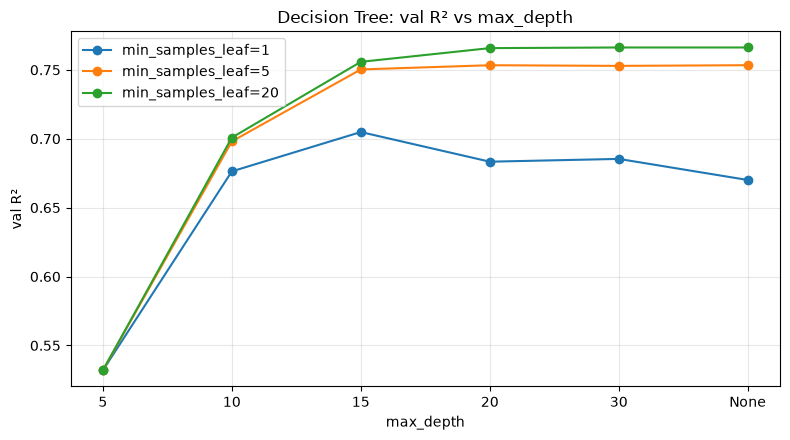


DT tuned — test: {'R2': 0.7746, 'RMSE': 471505.9359, 'MAE': 234350.2484, 'MAPE': 17.7422}


In [4]:
dt_grid = []
for md in [5, 10, 15, 20, 30, None]:
    for msl in [1, 5, 20]:
        m = DecisionTreeRegressor(max_depth=md, min_samples_leaf=msl, random_state=RANDOM_STATE)
        m.fit(Xtr, y_train)
        dt_grid.append({'max_depth': md, 'min_samples_leaf': msl,
                        'val_R2': r2_score(y_val, m.predict(Xva))})
dt_grid = pd.DataFrame(dt_grid).sort_values('val_R2', ascending=False)
print(dt_grid.round(4).to_string(index=False))

best = dt_grid.iloc[0]
print(f"\nbest: max_depth={best['max_depth']}, min_samples_leaf={int(best['min_samples_leaf'])}, "
      f"val R²={best['val_R2']:.4f}")

# Val R² vs depth, one curve per min_samples_leaf
plot_df = dt_grid.copy()
plot_df['depth_lab'] = plot_df['max_depth'].apply(lambda v: 'None' if pd.isna(v) else str(int(v)))
order_labs = ['5', '10', '15', '20', '30', 'None']
fig, ax = plt.subplots(figsize=(8, 4.5))
for msl, g in plot_df.groupby('min_samples_leaf'):
    g = g.set_index('depth_lab').reindex(order_labs)
    ax.plot(order_labs, g['val_R2'].values, marker='o', label=f'min_samples_leaf={int(msl)}')
ax.set_xlabel('max_depth'); ax.set_ylabel('val R²')
ax.set_title('Decision Tree: val R² vs max_depth')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

dt_best = DecisionTreeRegressor(
    max_depth=None if pd.isna(best['max_depth']) else int(best['max_depth']),
    min_samples_leaf=int(best['min_samples_leaf']), random_state=RANDOM_STATE)
dt_best.fit(Xtr, y_train)
record('DT tuned', 'test', y_test, dt_best.predict(Xte))
print('\nDT tuned — test:', {k: round(v, 4) for k, v in metrics(y_test, dt_best.predict(Xte)).items()})


## 3. Random Forest — variance reduction by averaging

A random forest averages hundreds of trees, each trained on a bootstrap sample with each split considering only a random subset of features. Averaging cancels much of a single tree's variance while keeping its nonlinearity. Expect **train R² well below 1.0** (unlike the lone tree) and the best val/test numbers so far — *if* the price signal has nonlinear structure that OLS missed.

In [5]:
rf_default = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
rf_default.fit(Xtr, y_train)
print(f'fit time: {time.time() - t0:.1f}s')
for split, X, y in [('train', Xtr, y_train), ('val', Xva, y_val), ('test', Xte, y_test)]:
    record('RF default (200 trees)', split, y, rf_default.predict(X))
d = pd.DataFrame(rows)
print(d[d['model'] == 'RF default (200 trees)'].set_index('split').round(4).to_string())


fit time: 10.9s
                        model      R2         RMSE          MAE     MAPE
split                                                                   
train  RF default (200 trees)  0.9808  132769.4287   63383.7070   4.9886
val    RF default (200 trees)  0.8602  354949.5946  175511.5724  13.7406
test   RF default (200 trees)  0.8561  376785.8739  184715.0836  14.2844


### 3b. Tuning the forest on validation

Small grid (6 fits — forests are slower; each fit prints its wall time). Scored by **val R²**; test stays locked. If this feels slow, shrink the grid — the pattern matters more than the exact optimum.

In [6]:
rf_grid = []
for md in [None, 20, 40]:
    for msl in [1, 5]:
        m = RandomForestRegressor(n_estimators=200, max_depth=md, min_samples_leaf=msl,
                                  random_state=RANDOM_STATE, n_jobs=-1)
        t0 = time.time()
        m.fit(Xtr, y_train)
        rf_grid.append({'max_depth': md, 'min_samples_leaf': msl,
                        'val_R2': r2_score(y_val, m.predict(Xva)),
                        'fit_s': round(time.time() - t0, 1)})
rf_grid = pd.DataFrame(rf_grid).sort_values('val_R2', ascending=False)
print(rf_grid.to_string(index=False))

rbest = rf_grid.iloc[0]
print(f"\nbest: max_depth={rbest['max_depth']}, min_samples_leaf={int(rbest['min_samples_leaf'])}, "
      f"val R²={rbest['val_R2']:.4f}")

rf_best = RandomForestRegressor(
    n_estimators=200,
    max_depth=None if pd.isna(rbest['max_depth']) else int(rbest['max_depth']),
    min_samples_leaf=int(rbest['min_samples_leaf']),
    random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
rf_best.fit(Xtr, y_train)
print(f'refit time: {time.time() - t0:.1f}s')
record('RF tuned', 'test', y_test, rf_best.predict(Xte))
print('RF tuned — test:', {k: round(v, 4) for k, v in metrics(y_test, rf_best.predict(Xte)).items()})


 max_depth  min_samples_leaf   val_R2  fit_s
       NaN                 1 0.860248   11.0
      40.0                 1 0.860177   11.3
      20.0                 1 0.858801    9.7
       NaN                 5 0.855093    8.8
      40.0                 5 0.855088    9.3
      20.0                 5 0.854241    8.7

best: max_depth=nan, min_samples_leaf=1, val R²=0.8602
refit time: 11.5s
RF tuned — test: {'R2': 0.8561, 'RMSE': 376785.8739, 'MAE': 184715.0836, 'MAPE': 14.2844}


## 4. Do trees recover the 8 dropped features?

Week 4 dropped 8 features because they added nothing to a *linear* model. Trees can exploit interactions (e.g., pool × living area), so we refit the winning forest configuration on all **41 features** and compare test R². If 41 ≈ 33, the drop stands; if 41 clearly wins, the selection was linear-specific and deserves a revisit.

In [7]:
rf_41 = RandomForestRegressor(
    n_estimators=200,
    max_depth=None if pd.isna(rbest['max_depth']) else int(rbest['max_depth']),
    min_samples_leaf=int(rbest['min_samples_leaf']),
    random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
rf_41.fit(X_train, y_train)   # NOTE: full 41-feature matrices
print(f'fit time: {time.time() - t0:.1f}s')
record('RF tuned (41 feats)', 'test', y_test, rf_41.predict(X_test))
print('RF tuned (41 feats) — test:',
      {k: round(v, 4) for k, v in metrics(y_test, rf_41.predict(X_test)).items()})


fit time: 12.4s
RF tuned (41 feats) — test: {'R2': 0.8612, 'RMSE': 369981.2539, 'MAE': 180128.5227, 'MAPE': 13.7609}


## 5. What the forest learned — feature importance

`feature_importances_` = each feature's total impurity decrease, normalized. Compare against Week 4's linear ranking (`|coef| × std`): features **both** models love are robust signals; features **only the forest** loves are nonlinear/interaction effects that OLS could not see.

Top 15 by RF impurity importance:
BathroomsTotalInteger            0.2381
LivingArea                       0.1953
Longitude                        0.1238
Latitude                         0.1085
PostalCode                       0.0607
CountyOrParish                   0.0603
YearBuilt                        0.0334
StreetNumberNumeric              0.0319
City                             0.0290
MLSAreaMajor                     0.0217
Stories_was_missing              0.0169
AssociationFee                   0.0134
HighSchoolDistrict               0.0129
AssociationFee_was_missing       0.0103
MainLevelBedrooms_was_missing    0.0088


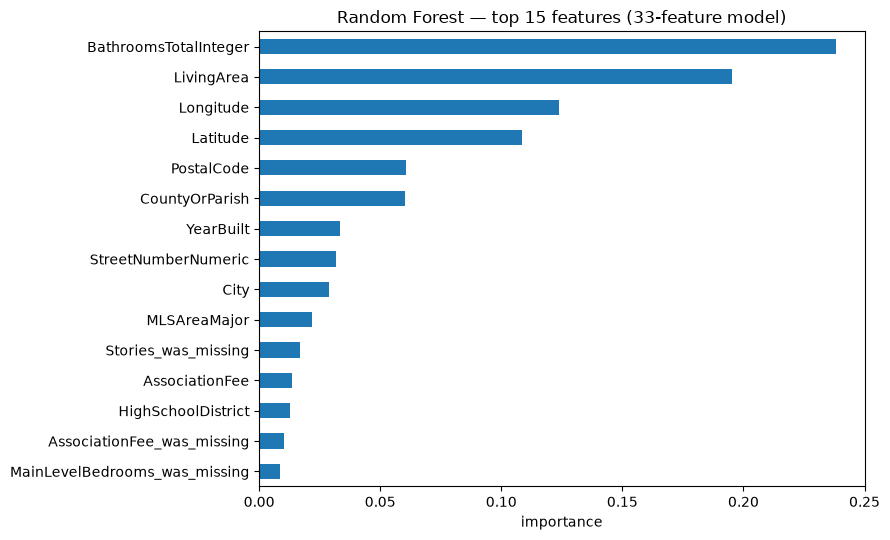

In [8]:
imp = pd.Series(rf_best.feature_importances_, index=selected).sort_values(ascending=False)
print('Top 15 by RF impurity importance:')
print(imp.head(15).round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 5.5))
imp.head(15).iloc[::-1].plot.barh(ax=ax)
ax.set_xlabel('importance')
ax.set_title('Random Forest — top 15 features (33-feature model)')
plt.tight_layout(); plt.show()


## 6. Diagnostics — where the best tree model breaks

Same battery as Week 4, on the test set, using the tuned forest's predictions. Residual = **actual − predicted** (negative = overprediction). Week 4's linear baseline showed: median residual −$32k (slight overprediction of ordinary homes), luxury systematically underpredicted, funnel-shaped heteroskedasticity. Does the forest fix any of that?

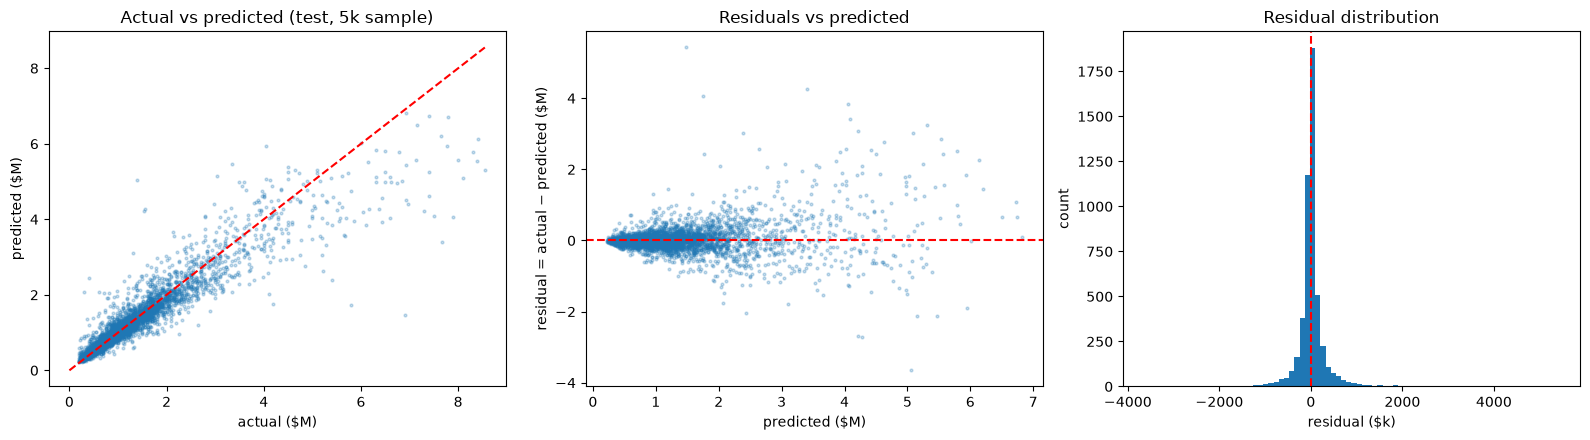

median residual: $2,478  (negative = systematic OVERprediction)
luxury share of test: 13.6%
luxury MAE:  $577,423  vs  overall MAE: $180,129
luxury mean actual:    $3,228,533  vs  luxury mean predicted: $2,896,128
hit rate within ±10%: 56.6%  (Week 4 baseline: 40.7%)


In [9]:
pred_best = rf_41.predict(X_test)   # champion: tuned RF on all 41 features

rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(y_test), size=min(5000, len(y_test)), replace=False)
yt, pt = y_test[idx], pred_best[idx]
resid = yt - pt

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(yt / 1e6, pt / 1e6, s=4, alpha=0.25)
lim = [0, max(yt.max(), pt.max()) / 1e6]
axes[0].plot(lim, lim, 'r--', lw=1.5)
axes[0].set_xlabel('actual ($M)'); axes[0].set_ylabel('predicted ($M)')
axes[0].set_title('Actual vs predicted (test, 5k sample)')

axes[1].scatter(pt / 1e6, resid / 1e6, s=4, alpha=0.25)
axes[1].axhline(0, color='r', ls='--', lw=1.5)
axes[1].set_xlabel('predicted ($M)'); axes[1].set_ylabel('residual = actual − predicted ($M)')
axes[1].set_title('Residuals vs predicted')

axes[2].hist(resid / 1e3, bins=80, edgecolor='none')
axes[2].axvline(0, color='r', ls='--', lw=1.5)
axes[2].set_xlabel('residual ($k)'); axes[2].set_ylabel('count')
axes[2].set_title('Residual distribution')
plt.tight_layout(); plt.show()

print(f'median residual: ${np.median(y_test - pred_best):,.0f}  (negative = systematic OVERprediction)')

lux = y_test > 2_000_000
print(f'luxury share of test: {lux.mean() * 100:.1f}%')
print(f'luxury MAE:  ${mean_absolute_error(y_test[lux], pred_best[lux]):,.0f}'
      f'  vs  overall MAE: ${mean_absolute_error(y_test, pred_best):,.0f}')
print(f'luxury mean actual:    ${y_test[lux].mean():,.0f}'
      f'  vs  luxury mean predicted: ${pred_best[lux].mean():,.0f}')

hit = np.mean(np.abs((y_test - pred_best) / y_test) <= 0.10) * 100
print(f'hit rate within ±10%: {hit:.1f}%  (Week 4 baseline: 40.7%)')


## 7. Model comparison — the table

Test metrics for every contender (`val_R2` included to read overfitting). The handbook asks for test R² vs baseline — that column decides.

In [11]:
comp = pd.DataFrame(rows)
order = ['Naive median(train)', 'LR (33 feats)', 'DT default', 'DT tuned',
         'RF default (200 trees)', 'RF tuned', 'RF tuned (41 feats)']
comp['model'] = pd.Categorical(comp['model'], categories=order, ordered=True)
test_tbl = comp[comp['split'] == 'test'].sort_values('model').set_index('model')
val_r2 = comp[comp['split'] == 'val'].set_index('model')['R2'].rename('val_R2')
test_tbl = test_tbl.join(val_r2)[['val_R2', 'R2', 'RMSE', 'MAE', 'MAPE']]
test_tbl.columns = ['val_R2', 'test_R2', 'test_RMSE', 'test_MAE', 'test_MAPE']

# 1) fill val_R2 where the winner's score is known from the tuning grids
#    (record() logged test only for refits; identical hyperparams/data/seed,
#     so the grid score applies exactly)
test_tbl.loc['DT tuned', 'val_R2'] = float(best['val_R2'])
test_tbl.loc['RF tuned', 'val_R2'] = float(rbest['val_R2'])
#    '/' where no val score was ever computed by design (Naive, RF-41)
test_tbl['val_R2'] = test_tbl['val_R2'].apply(lambda v: '/' if pd.isna(v) else round(float(v), 4))

# 2) feature count per model
test_tbl['n_features'] = test_tbl.index.map(
    {'Naive median(train)': '—', 'LR (33 feats)': 33, 'DT default': 33,
     'DT tuned': 33, 'RF default (200 trees)': 33, 'RF tuned': 33,
     'RF tuned (41 feats)': 41})

# 3) tuning re-selected the default config -> say so in the label
test_tbl = test_tbl.rename(index={'RF tuned': 'RF tuned (= default params)'})

test_tbl = test_tbl[['n_features', 'val_R2', 'test_R2', 'test_RMSE', 'test_MAE', 'test_MAPE']]
for c in ['test_R2', 'test_RMSE', 'test_MAE', 'test_MAPE']:
    test_tbl[c] = test_tbl[c].round(4)
print(test_tbl.to_string())
test_tbl.to_csv(OUT_DIR / 'model_comparison.csv')
print(f'\nsaved → {OUT_DIR / "model_comparison.csv"}')

                            n_features  val_R2  test_R2     test_RMSE     test_MAE  test_MAPE
model                                                                                        
Naive median(train)                  —       /  -0.1247  1.053302e+06  614448.2948    49.7170
LR (33 feats)                       33  0.5447   0.5570  6.610682e+05  419193.6546    40.6691
DT default                          33  0.6701   0.6997  5.442781e+05  258958.4577    19.8193
DT tuned                            33  0.7662   0.7746  4.715059e+05  234350.2484    17.7422
RF default (200 trees)              33  0.8602   0.8561  3.767859e+05  184715.0836    14.2844
RF tuned (= default params)         33  0.8602   0.8561  3.767859e+05  184715.0836    14.2844
RF tuned (41 feats)                 41       /   0.8612  3.699813e+05  180128.5227    13.7609

saved → output_week5/model_comparison.csv


## 8. Strengths / weaknesses — behavior notes for the write-up
- **Decision Tree (default):** train R² 0.9997 (101,388 leaves ≈ one per training row) vs val 0.6701 = pure memorization, as predicted. Tuned (min_samples_leaf=20) closed the gap to val 0.7662 / test 0.7746, but a single tree's piecewise-constant predictions remain jagged — it cannot extrapolate beyond the training range, so luxury homes (a sparse region) get the nearest leaf's mean. Strength: fully interpretable splits. Weakness: high variance, weak generalization.
- **Random Forest:** averaging + feature subsampling cut the train→val gap from 0.33 (single tree) to 0.12. Best test R² of the week (0.8612, 41 features), confirming the price signal has strong nonlinear structure — location rectangles from lat/lon, diminishing returns on bathrooms, bedrooms × living area interactions. Strengths: robust, needed no tuning (the grid re-selected the default config), natively handles mixed one-hot/frequency features. Weaknesses: still cannot extrapolate — the luxury underprediction from Week 4 persists but shrank (luxury mean predicted 2.90M vs actual 3.23M, ~10% low); predictions compress toward the mean at the extremes; slower and less interpretable than OLS.
- **33 vs 41 features (§4):** the 41-feature forest won marginally (test R² 0.8612 vs 0.8561, all four metrics moved together) — the dropped 8 do carry interaction signal that a linear screen cannot see. Week 4's selection stands for the linear model only; feature selection is model-dependent. Going forward: 41 features for tree-based models.
- **Vs baseline:** the frozen bar was test R² = 0.5569 (LR). The forest's +0.30 says nonlinearity dominates what the linear form can express on these features — a bigger leap than any feature-selection or tuning move this week.


In [12]:
joblib.dump(rf_41, OUT_DIR / 'rf_tuned_41f.joblib')
np.save(OUT_DIR / 'rf_tuned_41f_test_pred.npy', pred_best)

best_md = 'None' if pd.isna(rbest['max_depth']) else int(rbest['max_depth'])
base = pd.DataFrame(rows)
summary = [
    'Week 5 — Decision Tree + Random Forest (California close-price prediction)',
    f'Date: {pd.Timestamp.now().date()}',
    f'Features: 41 (full set) | train {X_train.shape[0]:,} / val {X_val.shape[0]:,} / test {X_test.shape[0]:,}',
    'Frozen baseline to beat: test R² = 0.5569 (Week 4, 41-feature OLS)',
    '',
    base[base['split'] == 'test'].set_index('model').round(4).to_string(),
    '',
    f"Best model: RF tuned on 41 features (max_depth={best_md}, "
    f"min_samples_leaf={int(rbest['min_samples_leaf'])}, n_estimators=200)",
    'Note: 33-feature RF test R² = 0.8561; the dropped 8 add +0.005 via interactions (section4).',
    f'Median residual (test): ${np.median(y_test - pred_best):,.0f} (negative = overprediction)',
]
(OUT_DIR / 'week5_summary.txt').write_text('\n'.join(summary))
print('\n'.join(summary))
print(f'\nsaved: rf_tuned_41f.joblib, rf_tuned_41f_test_pred.npy, week5_summary.txt → {OUT_DIR}/')

Week 5 — Decision Tree + Random Forest (California close-price prediction)
Date: 2026-10-19
Features: 41 (full set) | train 105,974 / val 11,416 / test 12,339
Frozen baseline to beat: test R² = 0.5569 (Week 4, 41-feature OLS)

                       split      R2          RMSE          MAE     MAPE
model                                                                   
Naive median(train)     test -0.1247  1.053302e+06  614448.2948  49.7170
LR (33 feats)           test  0.5570  6.610682e+05  419193.6546  40.6691
DT default              test  0.6997  5.442781e+05  258958.4577  19.8193
DT tuned                test  0.7746  4.715059e+05  234350.2484  17.7422
RF default (200 trees)  test  0.8561  3.767859e+05  184715.0836  14.2844
RF tuned                test  0.8561  3.767859e+05  184715.0836  14.2844
RF tuned (41 feats)     test  0.8612  3.699813e+05  180128.5227  13.7609

Best model: RF tuned on 41 features (max_depth=None, min_samples_leaf=1, n_estimators=200)
Note: 33-feature RF test

## 9. What's next — Week 6: Feature Engineering
- **Interaction features:** bed/bath ratio, property age (2026 − YearBuilt) — the forest's importance ranking hints at which interactions matter.
- **Geography:** school-district layer via spatial join on lat/lon (handbook Week 6).
- **Target transform:** log(ClosePrice) compresses the right tail and calms heteroskedasticity — a classic companion to Week 7's GBM tuning.